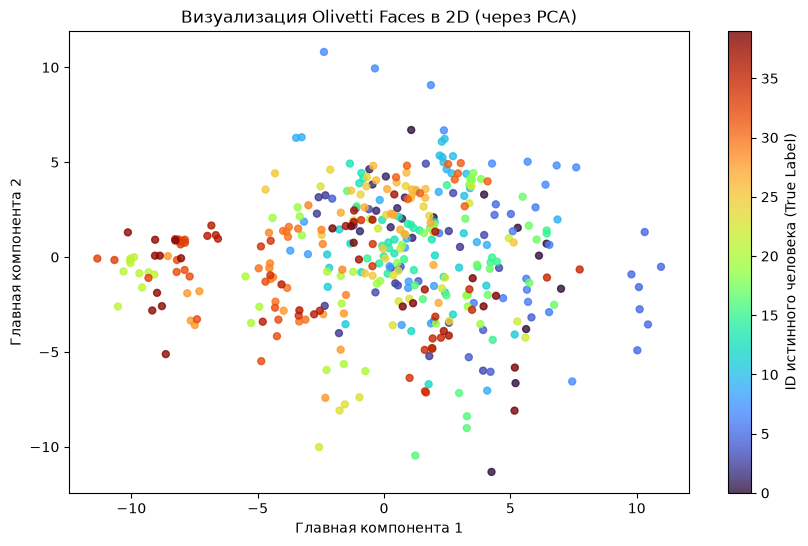

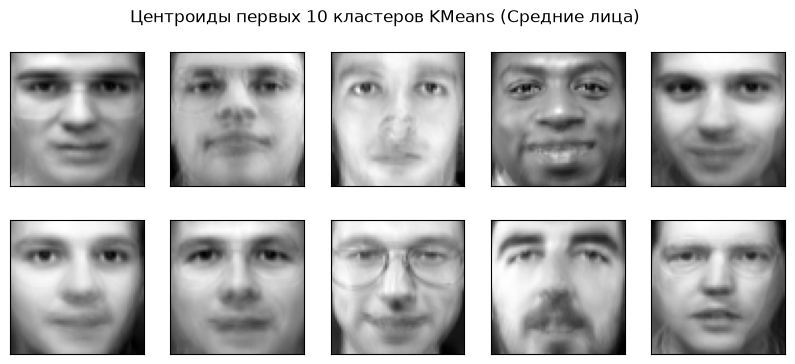

In [ ]:
from sklearn.datasets import fetch_olivetti_faces
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA  # Добавили для правильного 2D
import matplotlib.pyplot as plt
import numpy as np

# 1. Загрузка данных
faces = fetch_olivetti_faces()
X = faces.data
y = faces.target

# 2. Правильное снижение размерности до 2D с помощью PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

# 3. Кластеризация (выставляем 40 кластеров, так как в датасете 40 людей)
n_clusters = 40  
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X)

# 4. Визуализация датасета в двумерном пространстве (Используем X_pca!)
plt.figure(figsize=(10, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='turbo', s=25, alpha=0.8)
plt.title('Визуализация Olivetti Faces в 2D (через PCA)')
plt.xlabel('Главная компонента 1')
plt.ylabel('Главная компонента 2')
plt.colorbar(label='ID истинного человека (True Label)') # Исправили подпись
plt.show()

# 5. Визуализация центров кластеров (выведем первые 10 для компактности)
fig, axs = plt.subplots(2, 5, figsize=(10, 4), subplot_kw={'xticks': [], 'yticks': []})
for ax, center_face in zip(axs.ravel(), kmeans.cluster_centers_[:10]):
    # Восстанавливаем форму изображения из вектора 4096 -> 64x64
    ax.imshow(center_face.reshape(64, 64), cmap='gray')
plt.suptitle('Центроиды первых 10 кластеров KMeans (Средние лица)')
plt.show()
